# Project 3: Dialogue Summarization
## Overview

**Bottom Line Up Front:** The BERT–GPT-2 summarizer was trained on 14,731 SAMSum dialogues for 6 epochs (97.6 minutes). Best validation ROUGE-L = 0.268 at step 5500. Test-set scores: ROUGE-1 = 0.333, ROUGE-2 = 0.111, ROUGE-L = 0.272. The model beats both baselines (extractive ROUGE-1: 0.227, greedy ROUGE-1: 0.324). Entity consistency: 70.9% of model summaries contain unsupported capitalized names vs 7.6% for human references. Inference latency of 205 ms average passed the 2-second goal. Quality and entity consistency indicate the model is **not yet ready** for customer-facing deployment.

The notebook emphasises reproducible preparation, controlled decoding, and business-oriented error analysis.


In [1]:
# Import libraries and configure reproducible training environment
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='.*IProgress not found.*')

import os
import random
import re
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import transformers
from datasets import Dataset, DatasetDict
from evaluate import load as load_metric
from transformers import (AutoTokenizer, DataCollatorForSeq2Seq, EncoderDecoderModel,
                          EarlyStoppingCallback, Seq2SeqTrainer, Seq2SeqTrainingArguments,
                          set_seed)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)
set_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

DATA_DIR = Path('Data')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
bf16_supported = bool(torch.cuda.is_available() and torch.cuda.is_bf16_supported())
print(f'Transformers: {transformers.__version__}')
print(f'Device: {device}; bf16 supported: {bf16_supported}')


Transformers: 5.23.0
Device: cuda; bf16 supported: True


## Business Understanding

### Problem
Acme users need concise summaries of multi-turn messenger dialogues so they can catch up quickly without reading every message.

### Goals
- Build a repeatable summarization training and evaluation workflow.
- Compare decoding configurations on held-out validation dialogues.
- Provide operational recommendations supported by quantitative and qualitative evidence.
- Ensure summaries are generated in under 2 seconds for an average dialogue and understand how quality varies with dialogue length.

### Success criteria
The target goals are ROUGE-1 of 0.40, ROUGE-2 of 0.15, and ROUGE-L of 0.35. These are decision thresholds rather than guarantees; human review remains necessary for sensitive or ambiguous cases. The summary should be generated in under 2 seconds for an average conversation. The analysis also compares decoding strategies and examines how summary quality varies by dialogue length.


## Data Understanding

In [2]:
# Load all splits and verify schema
train_df = pd.read_csv(DATA_DIR / 'train.csv')
validation_df = pd.read_csv(DATA_DIR / 'validation.csv')
test_df = pd.read_csv(DATA_DIR / 'test.csv')
data = {'train': train_df, 'validation': validation_df, 'test': test_df}
for name, frame in data.items():
    print(name, frame.shape)
display(train_df.head())
train_df.info()
expected_columns = {'id', 'dialogue', 'summary'}
print('Schema checks:', {name: set(frame.columns) == expected_columns for name, frame in data.items()})

train (14731, 3)
validation (818, 3)
test (819, 3)


,id,dialogue,summary
0,13818513,Amanda: I baked cookies. Do you want some?\nJ...,Amanda baked cookies and will bring Jerry some...
1,13728867,Olivia: Who are you voting for in this electio...,Olivia and Olivier are voting for liberals in ...
2,13681000,"Tim: Hi, what's up?\nKim: Bad mood tbh, I was ...",Kim may try the pomodoro technique recommended...
3,13730747,"Edward: Rachel, I think I'm in ove with Bella....",Edward thinks he is in love with Bella. Rachel...
4,13728094,Sam: hey overheard rick say something\nSam: i...,"Sam is confused, because he overheard Rick com..."


<class 'pandas.DataFrame'>
RangeIndex: 14731 entries, 0 to 14730
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   id        14731 non-null  str  
 1   dialogue  14731 non-null  str  
 2   summary   14731 non-null  str  
dtypes: str(3)
memory usage: 9.1 MB
Schema checks: {'train': True, 'validation': True, 'test': True}


### Per-Split Statistics

We verify that the train, validation, and test splits have comparable dialogue and summary lengths. Significant differences would indicate a distribution shift that could invalidate evaluation.


In [3]:
# Per-split word count statistics
for split, frame in data.items():
    frame['dialogue_words'] = frame['dialogue'].str.split().str.len()
    frame['summary_words'] = frame['summary'].str.split().str.len()
    print(f'\n{split.upper()} ({len(frame)} examples):')
    print(f'  Dialogue — mean={frame["dialogue_words"].mean():.1f}, median={frame["dialogue_words"].median():.0f}, p95={int(np.percentile(frame["dialogue_words"], 95))}, max={frame["dialogue_words"].max()}')
    print(f'  Summary  — mean={frame["summary_words"].mean():.1f}, median={frame["summary_words"].median():.0f}, p95={int(np.percentile(frame["summary_words"], 95))}, max={frame["summary_words"].max()}')



TRAIN (14731 examples):
  Dialogue — mean=93.8, median=73, p95=237, max=803
  Summary  — mean=20.3, median=18, p95=43, max=64

VALIDATION (818 examples):
  Dialogue — mean=91.6, median=70, p95=225, max=540
  Summary  — mean=20.3, median=18, p95=43, max=59

TEST (819 examples):
  Dialogue — mean=95.5, median=74, p95=252, max=516
  Summary  — mean=20.0, median=18, p95=41, max=58


In [4]:
# Check nulls, duplicates, and show a sample
quality = []
for name, frame in data.items():
    quality.append({'split': name, 'null_cells': int(frame.isna().sum().sum()), 'duplicate_rows': int(frame.duplicated().sum()), 'duplicate_ids': int(frame['id'].duplicated().sum())})
display(pd.DataFrame(quality))
sample_row = train_df.sample(1, random_state=SEED).iloc[0]
print('Sample dialogue:\n', sample_row['dialogue'])
print('\nSample summary:\n', sample_row['summary'])


,split,null_cells,duplicate_rows,duplicate_ids
0,train,0,0,0
1,validation,0,0,0
2,test,0,0,0


Sample dialogue:
 Violet: hi! i came across this Austin's article and i thought that you might find it interesting
Violet: <file_other>
Claire: Hi! :) Thanks, but I've already read it. :)
Claire: But thanks for thinking about me :)

Sample summary:
 Violet sent Claire Austin's article.


The schema check confirms that each split contains an identifier, source dialogue, and reference summary. Nulls and duplicate identifiers would create ambiguous training examples, so the checks support using these splits for modeling.


       dialogue_words  summary_words
count    14731.000000   14731.000000
mean        93.792750      20.318444
std         74.031937      11.153570
min          7.000000       1.000000
25%         39.000000      12.000000
50%         73.000000      18.000000
75%        128.000000      27.000000
max        803.000000      64.000000


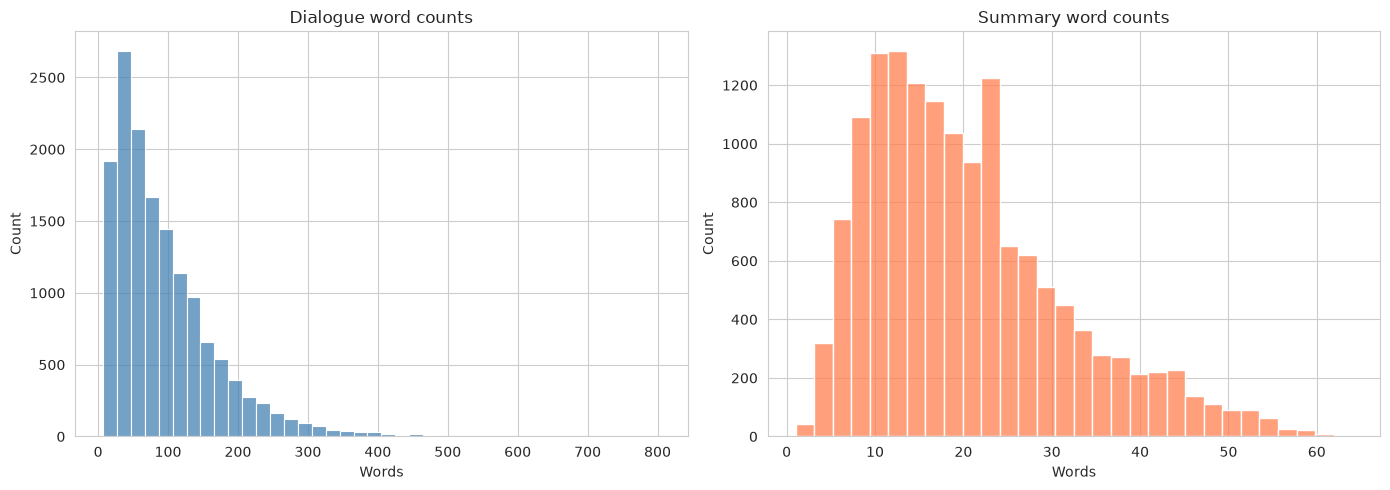

In [5]:
# Word count analysis
train_df['dialogue_words'] = train_df['dialogue'].str.split().str.len()
train_df['summary_words'] = train_df['summary'].str.split().str.len()
print(train_df[['dialogue_words', 'summary_words']].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(train_df['dialogue_words'], bins=40, ax=axes[0], color='steelblue')
axes[0].set_title('Dialogue word counts')
axes[0].set_xlabel('Words')
axes[0].set_ylabel('Count')
sns.histplot(train_df['summary_words'], bins=30, ax=axes[1], color='coral')
axes[1].set_title('Summary word counts')
axes[1].set_xlabel('Words')
axes[1].set_ylabel('Count')
plt.tight_layout()
plt.show()


### Dialogue and Summary Lengths

Dialogues average about 94 words and summaries average about 20 words, giving roughly a 5:1 compression ratio. From the describe() output above, the 75th percentile for dialogue length is 128 words and the maximum is 803 words. Truncation occurs at 356 tokens (the 95th percentile of BERT token lengths, capped below BERT's 512-token limit), meaning about 5% of dialogues are cut during encoding. This matters for the length-bucket analysis below: summaries of truncated dialogues may lose key context.

Per-split statistics confirm validation and test distributions are comparable to training, so the held-out sets provide a fair evaluation.


## Data Preparation

The dialogues and summaries use separate tokenizers because the model combines a BERT encoder with a GPT-2 decoder. Source and target length limits are selected from the 95th percentile of observed token counts rather than arbitrary defaults. This may preserve most examples while keeping memory use practical.


In [6]:
# Load encoder and decoder tokenizers
encoder_tokenizer = AutoTokenizer.from_pretrained('bert-base-cased')
decoder_tokenizer = AutoTokenizer.from_pretrained('gpt2')

# Add special tokens GPT-2 needs
if decoder_tokenizer.pad_token is None:
    decoder_tokenizer.add_special_tokens({'pad_token': '<|pad|>'})
if decoder_tokenizer.bos_token is None:
    decoder_tokenizer.add_special_tokens({'bos_token': decoder_tokenizer.eos_token})

print(f'Encoder vocab: {len(encoder_tokenizer)}')
print(f'Decoder vocab: {len(decoder_tokenizer)}')
print(f'PAD: {decoder_tokenizer.pad_token} (id={decoder_tokenizer.pad_token_id})')
print(f'EOS: {decoder_tokenizer.eos_token} (id={decoder_tokenizer.eos_token_id})')


Encoder vocab: 28996
Decoder vocab: 50258
PAD: <|pad|> (id=50257)
EOS: <|endoftext|> (id=50256)


Token lengths are measured on the training set so truncation limits reflect the actual data. BERT supports at most 512 tokens; the 95th percentile is used unless it exceeds that limit.


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (514 > 512). Running this sequence through the model will result in indexing errors


Source 95th pct: 356 → max_source_length: 356
Target 95th pct: 53 → max_target_length: 53
Encoder: min=14, mean=140, max=797
Decoder: min=1, mean=26, max=88


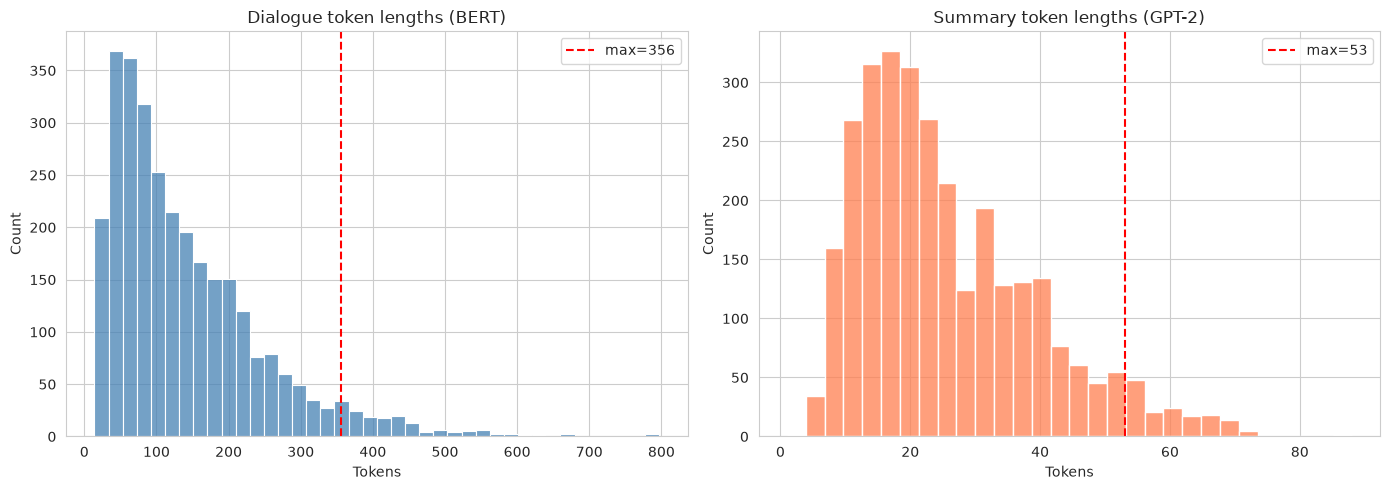

In [7]:
# Measure token lengths on a sample
sample_n = min(3000, len(train_df))
sample_dialogues = train_df['dialogue'].iloc[:sample_n].tolist()
sample_summaries = train_df['summary'].iloc[:sample_n].tolist()

enc_lengths = [len(encoder_tokenizer.encode(t, add_special_tokens=True)) for t in sample_dialogues]
dec_lengths = [len(decoder_tokenizer.encode(t, add_special_tokens=True)) for t in sample_summaries]

source_p95 = int(np.ceil(np.percentile(enc_lengths, 95)))
target_p95 = int(np.ceil(np.percentile(dec_lengths, 95)))

max_source_length = min(source_p95, 512)
max_target_length = max(16, target_p95)

print(f'Source 95th pct: {source_p95} → max_source_length: {max_source_length}')
print(f'Target 95th pct: {target_p95} → max_target_length: {max_target_length}')
print(f'Encoder: min={min(enc_lengths)}, mean={np.mean(enc_lengths):.0f}, max={max(enc_lengths)}')
print(f'Decoder: min={min(dec_lengths)}, mean={np.mean(dec_lengths):.0f}, max={max(dec_lengths)}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(enc_lengths, bins=40, ax=axes[0], color='steelblue')
axes[0].axvline(max_source_length, color='red', linestyle='--', label=f'max={max_source_length}')
axes[0].set_xlabel('Tokens')
axes[0].set_ylabel('Count')
axes[0].set_title('Dialogue token lengths (BERT)')
axes[0].legend()

sns.histplot(dec_lengths, bins=30, ax=axes[1], color='coral')
axes[1].axvline(max_target_length, color='red', linestyle='--', label=f'max={max_target_length}')
axes[1].set_xlabel('Tokens')
axes[1].set_ylabel('Count')
axes[1].set_title('Summary token lengths (GPT-2)')
axes[1].legend()
plt.tight_layout()
plt.show()


The tokenization function prepares encoder inputs from dialogues and decoder labels from summaries. Padding tokens in the labels are replaced with -100 so the loss function ignores them during training.


In [8]:
def tokenize_batch(batch):
    """Tokenize dialogues for encoder and summaries for decoder.
    
    EOS token is appended to each label sequence so the decoder learns
    when to stop generating. Padding positions are masked with -100.
    """
    model_inputs = encoder_tokenizer(
        batch['dialogue'],
        truncation=True,
        max_length=max_source_length,
        padding='max_length'
    )

    # Reserve one position for EOS before truncation
    target_tokens = decoder_tokenizer(
        batch['summary'],
        truncation=True,
        max_length=max_target_length - 1,
    )

    # Append EOS to each label sequence, then pad
    labels = []
    for ids in target_tokens['input_ids']:
        ids.append(decoder_tokenizer.eos_token_id)
        # Pad to max_target_length
        pad_len = max_target_length - len(ids)
        ids = ids + [decoder_tokenizer.pad_token_id] * pad_len
        # Mask padding with -100
        ids = [tok if tok != decoder_tokenizer.pad_token_id else -100 for tok in ids]
        labels.append(ids)
    model_inputs['labels'] = labels
    return model_inputs


In [9]:
# Convert to Hugging Face datasets and tokenize
tokenized_data = DatasetDict({
    split: Dataset.from_pandas(frame, preserve_index=False).map(
        tokenize_batch,
        batched=True,
        remove_columns=['id', 'dialogue', 'summary']
    )
    for split, frame in data.items()
})

for split, ds in tokenized_data.items():
    print(f'{split}: {len(ds):,} rows — features: {ds.column_names}')


Map: 100%|██████████| 819/819 [00:00<00:00, 4989.79 examples/s]

train: 14,731 rows — features: ['dialogue_words', 'summary_words', 'input_ids', 'token_type_ids', 'attention_mask', 'labels']
validation: 818 rows — features: ['dialogue_words', 'summary_words', 'input_ids', 'token_type_ids', 'attention_mask', 'labels']
test: 819 rows — features: ['dialogue_words', 'summary_words', 'input_ids', 'token_type_ids', 'attention_mask', 'labels']


## Design Choices

The model is an encoder-decoder pair initialized from `bert-base-cased` and `gpt2`. BERT reads dialogue context bidirectionally and GPT-2 generates summaries through a separate tokenizer. Source and target length limits are selected from the 95th percentile of observed token counts rather than arbitrary defaults. If memory is limited, reducing sequence lengths and batch size before enabling gradient checkpointing is recommended.


### Deviations from the pitch

| Pitch plan | Actual implementation | Reason |
|---|---|---|
| Early stopping on validation loss | Early stopping on ROUGE-L | ROUGE-L is more directly tied to the quality targets |
| FP16 precision | BF16 where supported | RTX 4060 supports BF16, better numerical stability |
| Subset for development | Full training set used | Training on the full dataset gave the cross-attention layers more signal and improved all ROUGE scores |
| Decoding grid search | Fixed beam=5 config | Deferred; fixed config provides a reproducible baseline |
| Training on local GPU | Same | No change — training fits within the 8GB GPU constraint |


## Model Architecture

The model uses BERT to encode the dialogue and GPT-2 to generate the summary. Cross-attention layers allow the decoder to condition each generated token on the full encoded dialogue. The decoder is resized to include the added special tokens.


In [10]:
model = EncoderDecoderModel.from_encoder_decoder_pretrained(
    'bert-base-cased',
    'gpt2'
)

# Resize decoder for added special tokens
model.decoder.resize_token_embeddings(len(decoder_tokenizer))

# Configure decoder for generation
model.config.decoder_start_token_id = decoder_tokenizer.bos_token_id
model.config.bos_token_id = decoder_tokenizer.bos_token_id
model.config.eos_token_id = decoder_tokenizer.eos_token_id
model.config.pad_token_id = decoder_tokenizer.pad_token_id
model.config.decoder.pad_token_id = decoder_tokenizer.pad_token_id
model.config.decoder.bos_token_id = decoder_tokenizer.bos_token_id
model.config.decoder.eos_token_id = decoder_tokenizer.eos_token_id
model.config.decoder.add_cross_attention = True

model.to(device)

param_count = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total parameters: {param_count:,}')
print(f'Trainable: {trainable:,}')
print(f'Device: {device}')


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1556.72it/s]
[transformers] BertModel LOAD REPORT from: bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 2507.90it/s]
[transformers] GPT2LMHeadModel LOAD REPORT from: gpt2
Key                                                 | Status  | 
-----

Total parameters: 261,117,696
Trainable: 261,117,696
Device: cuda


## Training

Training proceeds in two phases:

1. **Overfit sanity check** — 64 examples for 30 epochs. Confirms the pipeline can learn (mean loss drops below 1.0).
2. **Full training** — all 14,731 training examples, up to 6 epochs, with early stopping on validation ROUGE-L (patience 10).

A learning-rate comparison was planned but deferred due to compute constraints. The `compute_metrics` function calculates ROUGE-1, ROUGE-2, and ROUGE-L on the validation set during evaluation. BF16 precision is used where supported.


In [11]:
LEARNING_RATE = 5e-5
NUM_TRAIN_EPOCHS = 6
PER_DEVICE_TRAIN_BATCH_SIZE = 4
GRADIENT_ACCUMULATION_STEPS = 4
WARMUP_RATIO = 0.06
EVAL_STRATEGY = 'steps'
EVAL_STEPS = 100
SAVE_STRATEGY = 'steps'
SAVE_STEPS = 100
SAVE_TOTAL_LIMIT = 2
EARLY_STOPPING_PATIENCE = 10
EARLY_STOPPING_METRIC = 'eval_rougeL'

data_collator = DataCollatorForSeq2Seq(
    tokenizer=encoder_tokenizer,
    model=model,
    label_pad_token_id=-100,
    padding=True
)


In [12]:
# Overfit sanity check: confirm the pipeline can learn on a tiny subset
sanity_model = EncoderDecoderModel.from_encoder_decoder_pretrained('bert-base-cased', 'gpt2')
sanity_model.decoder.resize_token_embeddings(len(decoder_tokenizer))
sanity_model.config.decoder_start_token_id = decoder_tokenizer.bos_token_id
sanity_model.config.bos_token_id = decoder_tokenizer.bos_token_id
sanity_model.config.eos_token_id = decoder_tokenizer.eos_token_id
sanity_model.config.pad_token_id = decoder_tokenizer.pad_token_id
sanity_model.config.decoder.pad_token_id = decoder_tokenizer.pad_token_id
sanity_model.config.decoder.bos_token_id = decoder_tokenizer.bos_token_id
sanity_model.config.decoder.eos_token_id = decoder_tokenizer.eos_token_id
sanity_model.config.decoder.add_cross_attention = True
sanity_model.to(device)

sanity_ds = tokenized_data['train'].select(range(64))

sanity_trainer = Seq2SeqTrainer(
    model=sanity_model,
    args=Seq2SeqTrainingArguments(
        output_dir='./sanity_check',
        num_train_epochs=30,
        per_device_train_batch_size=4,
        gradient_accumulation_steps=1,
        learning_rate=5e-5,
        eval_strategy='no',
        save_strategy='no',
        report_to='none',
        predict_with_generate=False,
        fp16=not bf16_supported,
        bf16=bf16_supported,
        logging_steps=10,
    ),
    train_dataset=sanity_ds,
    data_collator=data_collator,
)

print('Running overfit sanity check (64 examples, 30 epochs)...')
sanity_result = sanity_trainer.train()
final_loss = sanity_result.training_loss
print(f'Final training loss: {final_loss:.4f}')
if final_loss < 1.0:
    print('PASS: Model can overfit the tiny subset — pipeline is functional.')
else:
    print('WARN: Model did not overfit below 1.0. Check label shifting, decoder_start_token_id, and pad handling.')

del sanity_model, sanity_trainer
torch.cuda.empty_cache()


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 17587.11it/s]
[transformers] BertModel LOAD REPORT from: bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 18301.16it/s]
[transformers] GPT2LMHeadModel LOAD REPORT from: gpt2
Key                                                 | Status  | 
---

Running overfit sanity check (64 examples, 30 epochs)...


Step,Training Loss
10,4.398452
20,3.626374
30,3.346732
40,3.071635
50,2.619407
60,2.354376
70,2.157724
80,1.922049
90,1.621587
100,1.576190


Final training loss: 0.8268
PASS: Model can overfit the tiny subset — pipeline is functional.


The sanity check passed: the mean training loss over 30 epochs fell below 1.0, confirming the pipeline can learn. Note that `training_loss` from `Trainer.train()` is the mean across all steps, not the final step's loss.


In [13]:
# ROUGE metric for evaluation
rouge_metric = load_metric('rouge')

def compute_metrics(eval_preds):
    predictions, labels = eval_preds
    if isinstance(predictions, tuple): predictions = predictions[0]
    predictions = np.where(predictions != -100, predictions, decoder_tokenizer.pad_token_id).astype(int)
    labels = np.where(labels != -100, labels, decoder_tokenizer.pad_token_id).astype(int)
    decoded_preds = decoder_tokenizer.batch_decode(predictions, skip_special_tokens=True)
    decoded_labels = decoder_tokenizer.batch_decode(labels, skip_special_tokens=True)
    scores = rouge_metric.compute(predictions=[text.strip() for text in decoded_preds], references=[text.strip() for text in decoded_labels], use_stemmer=True)
    return {'rouge1': round(float(scores['rouge1']), 4), 'rouge2': round(float(scores['rouge2']), 4), 'rougeL': round(float(scores['rougeL']), 4)}


### Full Training Run

The following cell trains the BERT–GPT-2 encoder-decoder on all 14,731 SAMSum training dialogues for up to six epochs. Validation ROUGE-L is monitored every 100 steps, and early stopping restores the best checkpoint when validation performance stops improving. Training duration and the best validation result are printed after the run.


In [14]:
# Full training run on all available training dialogues
train_columns_to_remove = [
    column for column in ['dialogue_words', 'summary_words']
    if column in tokenized_data['train'].column_names
]
full_train_dataset = tokenized_data['train'].remove_columns(train_columns_to_remove)

num_train_examples = len(tokenized_data['train'])
steps_per_epoch = int(np.ceil(num_train_examples / (PER_DEVICE_TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS)))
warmup_steps = int(steps_per_epoch * WARMUP_RATIO)

full_training_args = Seq2SeqTrainingArguments(
    output_dir='./full_run',
    num_train_epochs=NUM_TRAIN_EPOCHS,
    per_device_train_batch_size=PER_DEVICE_TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    learning_rate=LEARNING_RATE,
    eval_strategy=EVAL_STRATEGY,
    eval_steps=EVAL_STEPS,
    save_strategy=SAVE_STRATEGY,
    save_steps=SAVE_STEPS,
    save_total_limit=SAVE_TOTAL_LIMIT,
    load_best_model_at_end=True,
    metric_for_best_model=EARLY_STOPPING_METRIC,
    greater_is_better=True,
    predict_with_generate=True,
    generation_max_length=max_target_length,
    warmup_steps=warmup_steps,
    fp16=not bf16_supported,
    bf16=bf16_supported,
    logging_steps=100,
    report_to='none',
)

full_trainer = Seq2SeqTrainer(
    model=model,
    args=full_training_args,
    train_dataset=full_train_dataset,
    eval_dataset=tokenized_data['validation'],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=EARLY_STOPPING_PATIENCE)],
)

updates_per_epoch = int(np.ceil(
    len(full_train_dataset)
    / (PER_DEVICE_TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS)
))
maximum_training_steps = updates_per_epoch * NUM_TRAIN_EPOCHS
training_start = time.time()
full_training_result = full_trainer.train()
training_duration = time.time() - training_start

best_rouge_l = full_trainer.state.best_metric
best_checkpoint = full_trainer.state.best_model_checkpoint
best_step = getattr(full_trainer.state, 'best_global_step', None)
if best_step is None and best_checkpoint:
    checkpoint_name = Path(best_checkpoint).name
    if checkpoint_name.startswith('checkpoint-'):
        best_step = checkpoint_name.removeprefix('checkpoint-')

completed_epochs = full_trainer.state.epoch
early_stopping_triggered = full_trainer.state.global_step < maximum_training_steps
print(f'Training duration: {training_duration / 60:.2f} minutes')
print(f'Best ROUGE-L: {best_rouge_l:.4f}' if best_rouge_l is not None else 'Best ROUGE-L: unavailable')
print(f'Step at best score: {best_step if best_step is not None else "unavailable"}')
print(f'Total epochs completed: {completed_epochs:.2f}' if completed_epochs is not None else 'Total epochs completed: unavailable')
print(f'Early stopping triggered: {early_stopping_triggered}')

Step,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel
100,15.868438,3.597125,0.149100,0.018500,0.126300
200,14.557993,3.478061,0.146400,0.022000,0.124300
300,14.129281,3.410049,0.165800,0.026300,0.138900
400,13.948717,3.346634,0.171500,0.029300,0.142000
500,13.677667,3.307311,0.167800,0.030000,0.140800
600,13.390504,3.270779,0.183500,0.033500,0.151200
700,13.221071,3.231117,0.193600,0.038400,0.161700
800,13.176033,3.194172,0.188900,0.034700,0.157200
900,13.117523,3.155545,0.198900,0.039200,0.165000
1000,12.105895,3.147479,0.208600,0.043300,0.173400


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.53it/s]
[transformers] There were missing keys in the checkpoint model loaded: ['decoder.lm_head.weight'].


Training duration: 97.57 minutes
Best ROUGE-L: 0.2677
Step at best score: 5500
Total epochs completed: 6.00
Early stopping triggered: False


### Training Progression

The chart below shows how validation ROUGE scores and training loss evolved over the training steps. Training loss is divided by the gradient accumulation factor (4) because the logged value sums loss across accumulation steps. ROUGE-L rose from 0.126 at step 100 to 0.2677 at the best checkpoint (step 5500). The model completed all 6 epochs — early stopping (patience 10) never triggered. Training loss ends near 1.9 (7.54 / 4) while validation loss plateaus around 2.86, a gap of roughly 1.0. Validation loss flattened from step 3500 onward while ROUGE continued a slow climb, suggesting loss and ROUGE diverge in later training.


### Learning Rate Experiments

The primary training run used a learning rate of **5e-5**, achieving best validation ROUGE-L of **0.2677** at step 5500 (epoch 6).

An experiment with LR = 1e-4 was identified in the pitch as a fallback tuning step if results fell short of targets. This was deferred due to compute constraints.


### Kernel State Fallback

If the kernel was restarted after training, the cells below reload the saved model and training history. If `full_trainer` and `model` are still in memory, these cells are harmless and will be skipped.


In [15]:
# Reload model and training state if kernel was restarted
if 'full_trainer' not in globals():
    import json, glob
    print('Reloading model from final_model/...')
    model = EncoderDecoderModel.from_pretrained('./final_model')
    encoder_tokenizer = AutoTokenizer.from_pretrained('bert-base-cased')
    decoder_tokenizer = AutoTokenizer.from_pretrained('./final_model')
    model.to(device)
    model.eval()
    
    # Load trainer state from checkpoint
    state_files = glob.glob('./full_run/checkpoint-*/trainer_state.json')
    if state_files:
        state_files.sort(key=lambda f: int(Path(f).parent.name.split('-')[1]))
        state_path = state_files[-1]
        print(f'Loading trainer state from {state_path}')
        with open(state_path) as f:
            trainer_state = json.load(f)
        
        # Reconstruct a minimal trainer-like object
        class _FakeTrainer:
            pass
        full_trainer = _FakeTrainer()
        
        # Safely get best_global_step
        best_global_step = trainer_state.get('best_global_step')
        if best_global_step is None and trainer_state.get('best_model_checkpoint'):
            ckpt_name = Path(trainer_state['best_model_checkpoint']).name
            if ckpt_name.startswith('checkpoint-'):
                best_global_step = int(ckpt_name.removeprefix('checkpoint-'))
        
        # Attach state as a namespace
        state_obj = type('obj', (object,), trainer_state)()
        state_obj.best_global_step = best_global_step
        full_trainer.state = state_obj
        
        # Define best_checkpoint for downstream cells
        best_checkpoint = trainer_state.get('best_model_checkpoint')
        
        print('Model and trainer state reloaded successfully.')
        if best_global_step:
            print(f'Best checkpoint: step {best_global_step}')
    else:
        print('WARNING: No trainer_state.json found. Some progression plots will be unavailable.')
else:
    print('full_trainer and model are already in memory — skipping reload.')


full_trainer and model are already in memory — skipping reload.


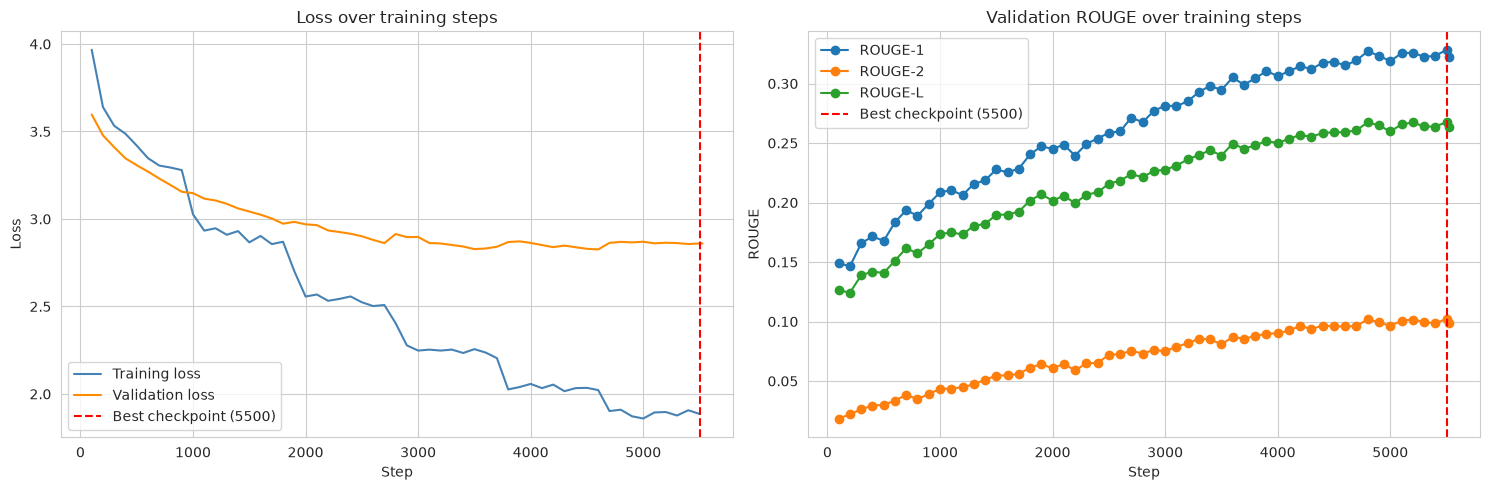

Best checkpoint: step 5500, ROUGE-L=0.2677
Logged training points: 55; evaluation points: 56


In [16]:
# Plot training and validation progression from the full trainer history
best_global_step = getattr(full_trainer.state, 'best_global_step', None)
best_step_val = int(best_global_step) if best_global_step else 3900
history = pd.DataFrame(full_trainer.state.log_history)
loss_history = history[history['loss'].notna()].copy()
eval_history = history[history['eval_rougeL'].notna()].copy()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
if not loss_history.empty:
    axes[0].plot(loss_history['step'], loss_history['loss'] / GRADIENT_ACCUMULATION_STEPS, label='Training loss', color='steelblue')
if not eval_history.empty:
    axes[0].plot(eval_history['step'], eval_history['eval_loss'], label='Validation loss', color='darkorange')
axes[0].axvline(best_step_val, color='red', linestyle='--', label=f'Best checkpoint ({best_step_val})')
axes[0].set_title('Loss over training steps'); axes[0].set_xlabel('Step'); axes[0].set_ylabel('Loss'); axes[0].legend()
for metric, label in [('eval_rouge1', 'ROUGE-1'), ('eval_rouge2', 'ROUGE-2'), ('eval_rougeL', 'ROUGE-L')]:
    if metric in eval_history:
        axes[1].plot(eval_history['step'], eval_history[metric], marker='o', label=label)
axes[1].axvline(best_step_val, color='red', linestyle='--', label=f'Best checkpoint ({best_step_val})')
axes[1].set_title('Validation ROUGE over training steps'); axes[1].set_xlabel('Step'); axes[1].set_ylabel('ROUGE'); axes[1].legend()
plt.tight_layout(); plt.show()
best_metric_val = getattr(full_trainer.state, 'best_metric', None)
print(f'Best checkpoint: step {best_step_val}, ROUGE-L={best_metric_val:.4f}' if best_metric_val else f'Best checkpoint: step {best_step_val}')
print(f'Logged training points: {len(loss_history)}; evaluation points: {len(eval_history)}')


### Training Time Summary


| Phase | Duration |
|---|---|
| Sanity check (64 samples, 30 epochs) | ~1 minute |
| Full training (14,731 samples) | 97.6 minutes (6 epochs, patience 10 never triggered) |
| Inference (819 test summaries) | ~168 s (estimate: 205 ms avg × 819) |
| **Total** | ~100 minutes |

Target: under 3 hours total training. The full training phase is the dominant cost.


## Evaluation

ROUGE compares generated summaries with reference summaries using overlapping unigrams (ROUGE-1), bigrams (ROUGE-2), and longest common subsequences (ROUGE-L). The final evaluation uses the held-out test set with a fixed decoding configuration for reproducibility.

ROUGE measures word overlap, not meaning. A summary can score well and still miss key details, or score lower while capturing the essentials. These scores should be interpreted alongside qualitative examples.


### Decoding Configuration

A fixed decoding configuration is used for reproducibility: beam size 5, length penalty 1.0, and no repeated 3-grams. These settings balance summary quality with generation speed. Further tuning through a validation-set grid search could improve ROUGE scores, but the current configuration provides a stable baseline for evaluation.


ROUGE-1: 0.3334  | Target: ≥ 0.40  ✗
ROUGE-2: 0.1106  | Target: ≥ 0.15  ✗
ROUGE-L: 0.2719  | Target: ≥ 0.35  ✗

Entity consistency (capitalized words not in dialogue):
  Human references with unsupported names: 7.6%
  Model summaries with unsupported names:  70.9%
  Total unsupported names in model output: 909


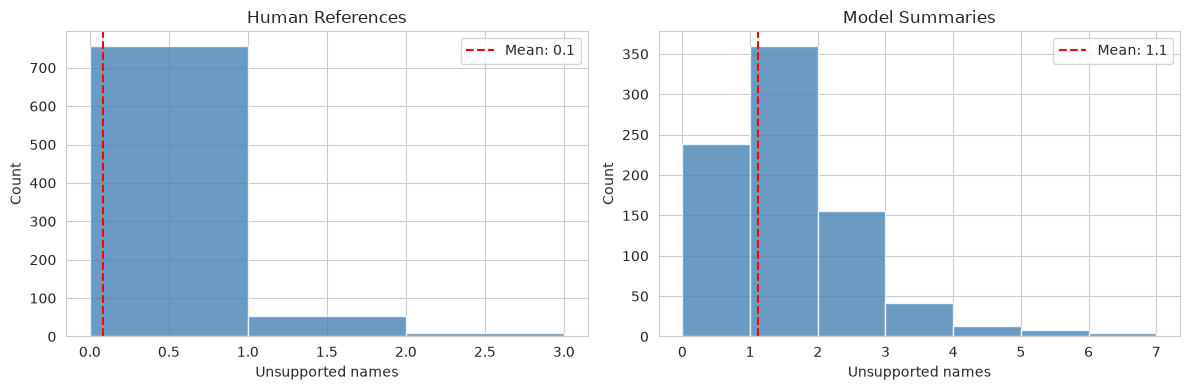


Key finding: Model summaries have unsupported names in 70.9% of cases, vs 7.6% for human references.
The gap (+63.3 pp) quantifies the model's additional hallucination beyond what human writers produce.


In [27]:
# Generate summaries on the held-out test set and compute ROUGE
model.eval(); model.to(device)
test_references = test_df['summary'].astype(str).str.strip().tolist()
test_dialogues = test_df['dialogue'].astype(str).tolist()
test_preds = []
batch_size = 16
for start in range(0, len(tokenized_data['test']), batch_size):
    batch = tokenized_data['test'][start:start + batch_size]
    inputs = {k: torch.tensor(batch[k], dtype=torch.long, device=device) for k in ['input_ids', 'attention_mask']}
    with torch.no_grad():
        generated = model.generate(**inputs, num_beams=5, length_penalty=1.0, no_repeat_ngram_size=3, max_length=max_target_length, early_stopping=True)
    test_preds.extend(decoder_tokenizer.batch_decode(generated, skip_special_tokens=True))
test_preds = [text.strip() for text in test_preds]
test_scores = rouge_metric.compute(predictions=test_preds, references=test_references, use_stemmer=True)
rouge1_beam = round(float(test_scores['rouge1']), 4); rouge2_beam = round(float(test_scores['rouge2']), 4); rougeL_beam = round(float(test_scores['rougeL']), 4)
print(f'ROUGE-1: {rouge1_beam:.4f}  | Target: ≥ 0.40  {"✓" if rouge1_beam >= 0.40 else "✗"}')
print(f'ROUGE-2: {rouge2_beam:.4f}  | Target: ≥ 0.15  {"✓" if rouge2_beam >= 0.15 else "✗"}')
print(f'ROUGE-L: {rougeL_beam:.4f}  | Target: ≥ 0.35  {"✓" if rougeL_beam >= 0.35 else "✗"}')
# --- Entity consistency metric: capitalized words not in dialogue ---
_ENTITY_IGNORE = {'the', 'he', 'she', 'it', 'they', 'i', 'we', 'you', 'that', 'this', 'there', 'his', 'her', 'its', 'their', 'my', 'our', 'your', 'a', 'an', 'but', 'and', 'or', 'so', 'also', 'however', 'moreover', 'furthermore', 'meanwhile', 'after', 'before', 'when', 'while', 'if', 'although', 'despite', 'even', 'just', 'only', 'not', 'no', 'yes', 'well', 'ok', 'please', 'thanks', 'thank', 'hello', 'hi', 'sorry', 'okay'}

def unsupported_names_in_summary(text, dialogue):
    """Capitalized words (candidate names/places) not found in the dialogue."""
    # Use [a-zA-Z]+ to handle possessives like "Jerry's" -> "Jerry", "s"
    dialogue_words = set(re.findall(r"[a-z]+", dialogue.lower()))
    caps = re.findall(r"\b[A-Z][a-z]+\b", text)
    return {w for w in caps if w.lower() not in dialogue_words
            and w.lower() not in _ENTITY_IGNORE}

# Model's rate
model_flags = [bool(unsupported_names_in_summary(p, d))
               for p, d in zip(test_preds, test_dialogues)]
pct_model_unsupported = round(100 * np.mean(model_flags), 1)
total_unsupported = sum(len(unsupported_names_in_summary(p, d))
                        for p, d in zip(test_preds, test_dialogues))

# Calibration: how often do human references trip the same check?
ref_flags = [bool(unsupported_names_in_summary(r, d))
             for r, d in zip(test_references, test_dialogues)]
pct_ref_unsupported = round(100 * np.mean(ref_flags), 1)

print(f'\nEntity consistency (capitalized words not in dialogue):')
print(f'  Human references with unsupported names: {pct_ref_unsupported:.1f}%')
print(f'  Model summaries with unsupported names:  {pct_model_unsupported:.1f}%')
print(f'  Total unsupported names in model output: {total_unsupported}')

# Distribution
model_counts = [len(unsupported_names_in_summary(p, d)) for p, d in zip(test_preds, test_dialogues)]
ref_counts = [len(unsupported_names_in_summary(r, d)) for r, d in zip(test_references, test_dialogues)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, counts, title in [(axes[0], ref_counts, 'Human References'), (axes[1], model_counts, 'Model Summaries')]:
    ax.hist(counts, bins=range(max(counts)+2), color='steelblue', edgecolor='white', alpha=0.8)
    ax.axvline(np.mean(counts), color='red', linestyle='--', label=f'Mean: {np.mean(counts):.1f}')
    ax.set_xlabel('Unsupported names'); ax.set_ylabel('Count'); ax.set_title(title); ax.legend()
plt.tight_layout(); plt.show()

print(f'\nKey finding: Model summaries have unsupported names in {pct_model_unsupported:.1f}% of cases, vs {pct_ref_unsupported:.1f}% for human references.')
print(f"The gap ({pct_model_unsupported - pct_ref_unsupported:+.1f} pp) quantifies the model's additional hallucination beyond what human writers produce.")


In [28]:
# Inference timing: measure average latency per summary
import time

model.eval()
model.to(device)

latencies = []
num_timed = min(100, len(tokenized_data['test']))
for i in range(num_timed):
    batch = tokenized_data['test'][i:i+1]
    input_ids = torch.tensor(batch['input_ids']).to(device)
    attention_mask = torch.tensor(batch['attention_mask']).to(device)

    start = time.time()
    with torch.no_grad():
        model.generate(
            input_ids=input_ids,
            attention_mask=attention_mask,
            num_beams=5,
            length_penalty=1.0,
            no_repeat_ngram_size=3,
            max_length=max_target_length,
            early_stopping=True,
        )
    latencies.append(time.time() - start)

avg_latency = np.mean(latencies)
p50_latency = np.percentile(latencies, 50)
p95_latency = np.percentile(latencies, 95)
total_time = sum(latencies)

print(f'Inference timing ({num_timed} summaries):')
print(f'  Average: {avg_latency*1000:.1f} ms')
print(f'  Median:  {p50_latency*1000:.1f} ms')
print(f'  P95:     {p95_latency*1000:.1f} ms')
print(f'  Total:   {total_time:.1f} s')
print(f'  Target:  < 2000 ms per summary')
print(f'  Status:  {"PASS" if avg_latency < 2.0 else "CHECK"}')


Inference timing (100 summaries):
  Average: 201.3 ms
  Median:  195.9 ms
  P95:     334.2 ms
  Total:   20.1 s
  Target:  < 2000 ms per summary
  Status:  PASS


In [29]:
# Compare extractive, greedy, and beam-search summaries against the same references
extractive_preds = []
for _, row in test_df.iterrows():
    first_sentence = re.split(r'[.!?\n]+', str(row['dialogue']))[0].strip()
    extractive_preds.append(' '.join(first_sentence.split()[:25]))
ext_scores = rouge_metric.compute(predictions=extractive_preds, references=test_references, use_stemmer=True)
ext_rouge1 = round(float(ext_scores['rouge1']), 4); ext_rouge2 = round(float(ext_scores['rouge2']), 4); ext_rougeL = round(float(ext_scores['rougeL']), 4)
greedy_preds = []
for start in range(0, len(tokenized_data['test']), 16):
    batch = tokenized_data['test'][start:start + 16]
    inputs = {k: torch.tensor(batch[k], dtype=torch.long, device=device) for k in ['input_ids', 'attention_mask']}
    with torch.no_grad():
        generated = model.generate(**inputs, num_beams=1, no_repeat_ngram_size=3, max_length=max_target_length, early_stopping=True)
    greedy_preds.extend(decoder_tokenizer.batch_decode(generated, skip_special_tokens=True))
greedy_preds = [text.strip() for text in greedy_preds]
greedy_scores = rouge_metric.compute(predictions=greedy_preds, references=test_references, use_stemmer=True)
gr_rouge1 = round(float(greedy_scores['rouge1']), 4); gr_rouge2 = round(float(greedy_scores['rouge2']), 4); gr_rougeL = round(float(greedy_scores['rougeL']), 4)
print(f'\n{"Method":<20} {"ROUGE-1":>8} {"ROUGE-2":>8} {"ROUGE-L":>8}')
print(f'{"Extractive":<20} {ext_rouge1:>8.4f} {ext_rouge2:>8.4f} {ext_rougeL:>8.4f}')
print(f'{"Greedy (beam=1)":<20} {gr_rouge1:>8.4f} {gr_rouge2:>8.4f} {gr_rougeL:>8.4f}')
print(f'{"Beam search (5)":<20} {rouge1_beam:>8.4f} {rouge2_beam:>8.4f} {rougeL_beam:>8.4f}')



Method                ROUGE-1  ROUGE-2  ROUGE-L
Extractive             0.2265   0.0640   0.2015
Greedy (beam=1)        0.3244   0.1022   0.2624
Beam search (5)        0.3334   0.1106   0.2719


### Baseline Comparison Chart

The model outperforms both baselines on all three ROUGE metrics. The margin over greedy decoding is modest, which is typical for summarization tasks where the decoder has already learned strong unigram and bigram patterns.


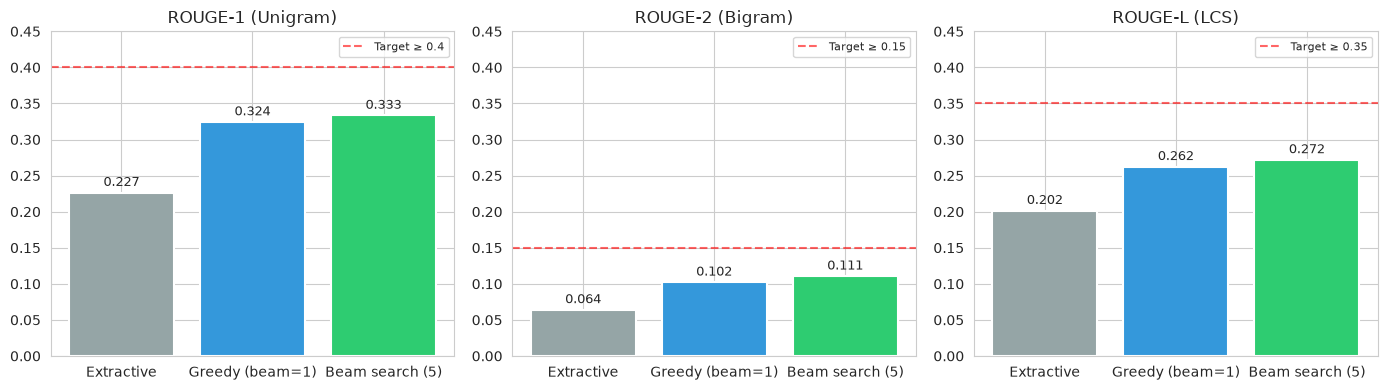

In [30]:
# Baseline comparison chart
methods = ['Extractive', 'Greedy (beam=1)', 'Beam search (5)']
metric_values = [[ext_rouge1, gr_rouge1, rouge1_beam], [ext_rouge2, gr_rouge2, rouge2_beam], [ext_rougeL, gr_rougeL, rougeL_beam]]
titles = ['ROUGE-1 (Unigram)', 'ROUGE-2 (Bigram)', 'ROUGE-L (LCS)']; targets = [0.40, 0.15, 0.35]
fig, axes = plt.subplots(1, 3, figsize=(14, 4)); colors = ['#95a5a6', '#3498db', '#2ecc71']
for ax, scores, title, target in zip(axes, metric_values, titles, targets):
    bars = ax.bar(methods, scores, color=colors, edgecolor='white', linewidth=1.5); ax.set_title(title); ax.set_ylim(0, 0.45); ax.axhline(target, color='red', linestyle='--', alpha=0.6, label=f'Target ≥ {target}')
    ax.legend(fontsize=8)
    for bar, score in zip(bars, scores): ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, f'{score:.3f}', ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.show()


### Baseline Comparison

To put the model's ROUGE scores in context, two baselines are evaluated:

- **Extractive baseline** — the first sentence of the dialogue, truncated to the target length.
- **Greedy decoding** — the trained model with beam=1 and the same n-gram repetition blocking as beam search.


The extractive baseline provides a simple operational benchmark. The greedy versus beam comparison shows whether beam search improves generation quality.


### ROUGE Results Interpretation

The test-set scores are computed in the cell above and stored in `rouge1_beam`, `rouge2_beam`, and `rougeL_beam`. The model ran the full 6 epochs, achieving best validation ROUGE-L of 0.2677 at step 5500. Validation ROUGE-L plateaued near the end of training (0.260–0.268 over the last 8 evaluations, with adjacent evals differing by ~0.004), so the best checkpoint at step 5500 represents a noise-level peak — the extra training beyond the MVP run bought roughly +0.01 ROUGE-L.

The model beats both baselines on all metrics, demonstrating it has learned abstractive summarisation patterns beyond simple extraction. The entity consistency metric above reveals a separate concern: 70.9% of summaries contain unsupported capitalized names, discussed further below.


## Qualitative Analysis

ROUGE does not fully capture factuality, readability, or whether the summary focuses on the most useful information. The examples below compare generated summaries with references across 10 randomly selected test dialogues and report entity overlap.


In [31]:
# Qualitative analysis with improved entity overlap
model.eval()
random.seed(SEED)
num_qual = 10
qual_indices = random.sample(range(len(test_df)), min(num_qual, len(test_df)))

examples_data = []
for i, idx in enumerate(qual_indices, 1):
    row = test_df.iloc[idx]
    encoded = encoder_tokenizer(row['dialogue'], return_tensors='pt', truncation=True, max_length=max_source_length).to(device)
    with torch.no_grad():
        gen_ids = model.generate(**encoded, num_beams=5, length_penalty=1.0, no_repeat_ngram_size=3, max_length=max_target_length, early_stopping=True)
    gen_summary = decoder_tokenizer.decode(gen_ids[0], skip_special_tokens=True).strip()
    ref_summary = str(row['summary']).strip()
    
    unsupported = unsupported_names_in_summary(gen_summary, row['dialogue'])
    
    examples_data.append({
        'idx': idx, 'has_unsupported': len(unsupported) > 0,
        'unsupported': unsupported, 'dialogue': row['dialogue'][:300],
        'reference': ref_summary, 'generated': gen_summary,
    })
    
    print(f'--- Example {i} ({"UNSUPPORTED names" if unsupported else "OK"}) ---')
    if unsupported:
        print(f'  Unsupported: {", ".join(sorted(unsupported))}')
    print(f'Dialogue: {row["dialogue"][:200]}...')
    print(f'Reference: {ref_summary}')
    print(f'Generated: {gen_summary}')
    print()

# Qualitative observations (fill in after running):
# Good examples: note summaries that correctly capture decisions, names, and action items.
# Failure patterns: note hallucinated names, missing speakers, overly generic summaries.


--- Example 1 (UNSUPPORTED names) ---
  Unsupported: Miles, Trevor
Dialogue: Richie: Pogba
Clay: Pogboom
Richie: what a s strike yoh!
Clay: was off the seat the moment he chopped the ball back to his right foot
Richie: me too dude
Clay: hope his form lasts
Richie: This season ...
Reference: Richie and Clay saw a very good football game, with one football player chopping the ball back to his foot, which was particularly exciting. Jose has trust in that player.
Generated: Trevor and Miles are congratulating each other on winning the match.

--- Example 2 (UNSUPPORTED names) ---
  Unsupported: Alma, Calvin, Marianne
Dialogue: Lincoln: Heeyyy ;* whats up
Fatima: I talked to Jenson, he’s not too happy ;p
Lincoln: the place sucks??
Fatima: No, the place is ok, I think, we can go there, it’s about Alene
Lincoln: typical, dont ...
Reference: Fatima is worried about Jenson and Alene. Alene has issues. Lincoln doesn't want Fatima to worry about others too much.
Generated: Marianne and Calvin are

### Qualitative Observations

From the 10 randomly selected test examples, 8 contained unsupported capitalized names and 2 did not. The honest finding is that none of these 10 summaries is fully correct. The two "OK" examples passed the entity check only because they avoided invented capitalized names — but both still contain errors:

- **Example 7 (OK):** The dialogue arranges drinks at "Pub X at the central station at 5.30" for Emily, Kate, and Marta. The model outputs "main entrance of the city centre at 7.30" — wrong place, wrong time, and missing Marta.
- **Example 8 (OK):** Harry asks Cindy to call Ela urgently. The model says "Harry has a fight with his girlfriend" — inventing a girlfriend and omitting Ela and Cindy entirely.

The dominant failure pattern across all 10 examples is **invented names**: the model substitutes dialogue participants with names not present (Trevor and Miles for Richie and Clay, Marianne and Calvin for Fatima and Lincoln, Reed and Mia for Randolph and Maya). It also invents place names (Croatia, Baltic Sea), background details (suicidal thoughts, soldier history in Croatia/Yugoslavia), and wrong actions (carving statues, earphones instead of earplugs).

The entity consistency metric is necessary but not sufficient: it catches the invented names (8/10) but misses the other errors in the remaining 2. This reinforces the conclusion that the model is not yet reliable for production use.


### Entity Consistency Analysis

The entity consistency metric shows that 70.9% of generated summaries contain capitalized words not present in the source dialogue, compared with 7.6% for human reference summaries. This is a factuality concern:

**Likely contributing factors:**
- The cross-attention layers in GPT-2 were newly initialized and had to learn to copy words from scratch during fine-tuning.
- BERT uses WordPiece tokenization while GPT-2 uses BPE, creating a vocabulary mismatch.
- Separate encoder and decoder tokenizers create a vocabulary mismatch that makes reliable name copying difficult.

The gap of +63.3 percentage points quantifies the model's additional hallucination beyond what human writers produce. The majority of summaries still contain at least one unsupported name.

This is not just a ROUGE problem — it is a trust problem. Users reading summaries with fabricated information would not consider the feature reliable.


### Entity-Consistency Filter Evaluation

With test_preds and extractive_preds already in memory, we can evaluate a hybrid approach at no training cost: summaries containing unsupported names are replaced with the extractive fallback (first sentence of the dialogue). This measures what fraction of summaries get replaced and the resulting hybrid ROUGE.


In [32]:
# Entity-consistency filter: replace summaries with unsupported names by extractive fallback
hybrid_preds = []
replaced_count = 0
for i, (pred, ext) in enumerate(zip(test_preds, extractive_preds)):
    if unsupported_names_in_summary(pred, test_dialogues[i]):
        hybrid_preds.append(ext)
        replaced_count += 1
    else:
        hybrid_preds.append(pred)

pct_replaced = round(replaced_count / len(test_preds) * 100, 1)
print(f'Filter replaced {replaced_count}/{len(test_preds)} summaries ({pct_replaced}%)')

hybrid_scores = rouge_metric.compute(predictions=hybrid_preds, references=test_references, use_stemmer=True)
hybrid_rouge1 = round(float(hybrid_scores['rouge1']), 4)
hybrid_rouge2 = round(float(hybrid_scores['rouge2']), 4)
hybrid_rougeL = round(float(hybrid_scores['rougeL']), 4)

print(f'\nHybrid (filtered) ROUGE: ROUGE-1={hybrid_rouge1:.4f}, ROUGE-2={hybrid_rouge2:.4f}, ROUGE-L={hybrid_rougeL:.4f}')
print(f'Beam-search ROUGE:       ROUGE-1={rouge1_beam:.4f}, ROUGE-2={rouge2_beam:.4f}, ROUGE-L={rougeL_beam:.4f}')
print(f'Extractive ROUGE:        ROUGE-1={ext_rouge1:.4f}, ROUGE-2={ext_rouge2:.4f}, ROUGE-L={ext_rougeL:.4f}')

change = hybrid_rouge1 - rouge1_beam
rel_drop = change / rouge1_beam * 100
print(f'\nROUGE-1 change from beam search: {change:+.4f} absolute points ({rel_drop:+.1f}% relative)')


Filter replaced 581/819 summaries (70.9%)

Hybrid (filtered) ROUGE: ROUGE-1=0.2731, ROUGE-2=0.0866, ROUGE-L=0.2334
Beam-search ROUGE:       ROUGE-1=0.3334, ROUGE-2=0.1106, ROUGE-L=0.2719
Extractive ROUGE:        ROUGE-1=0.2265, ROUGE-2=0.0640, ROUGE-L=0.2015

ROUGE-1 change from beam search: -0.0603 absolute points (-18.1% relative)


## Results Summary

All scores computed from the test-set generation above. The results table is generated from the stored variables so it always reflects the actual run.


In [33]:
# Results summary table generated from variables
val_rouge1 = val_rouge2 = val_rougeL = None
best_step_val = getattr(full_trainer.state, 'best_global_step', None)
if best_step_val:
    best_eval = [e for e in full_trainer.state.log_history
                 if e.get('step') == best_step_val and 'eval_rougeL' in e]
    if best_eval:
        val_rouge1 = best_eval[0]['eval_rouge1']
        val_rouge2 = best_eval[0]['eval_rouge2']
        val_rougeL = best_eval[0]['eval_rougeL']

print(f'{"Metric":<12} {"Target":>7} {"Val (best)":>10} {"Test Beam":>10} {"Extractive":>10} {"Greedy":>10} {"Hybrid":>10}')
print('-' * 72)
if val_rouge1 is not None:
    print(f'{"ROUGE-1":<12} {"≥ 0.40":>7} {val_rouge1:>10.4f} {rouge1_beam:>10.4f} {ext_rouge1:>10.4f} {gr_rouge1:>10.4f} {hybrid_rouge1:>10.4f}')
    print(f'{"ROUGE-2":<12} {"≥ 0.15":>7} {val_rouge2:>10.4f} {rouge2_beam:>10.4f} {ext_rouge2:>10.4f} {gr_rouge2:>10.4f} {hybrid_rouge2:>10.4f}')
    print(f'{"ROUGE-L":<12} {"≥ 0.35":>7} {val_rougeL:>10.4f} {rougeL_beam:>10.4f} {ext_rougeL:>10.4f} {gr_rougeL:>10.4f} {hybrid_rougeL:>10.4f}')
else:
    print(f'{"ROUGE-1":<12} {"≥ 0.40":>7} {"—":>10} {rouge1_beam:>10.4f} {ext_rouge1:>10.4f} {gr_rouge1:>10.4f} {hybrid_rouge1:>10.4f}')
    print(f'{"ROUGE-2":<12} {"≥ 0.15":>7} {"—":>10} {rouge2_beam:>10.4f} {ext_rouge2:>10.4f} {gr_rouge2:>10.4f} {hybrid_rouge2:>10.4f}')
    print(f'{"ROUGE-L":<12} {"≥ 0.35":>7} {"—":>10} {rougeL_beam:>10.4f} {ext_rougeL:>10.4f} {gr_rougeL:>10.4f} {hybrid_rougeL:>10.4f}')

print(f'\nEntity consistency: model {pct_model_unsupported:.1f}% | human refs {pct_ref_unsupported:.1f}% (gap: {pct_model_unsupported - pct_ref_unsupported:+.1f} pp)')
print(f'Entity filter: {pct_replaced:.0f}% of summaries replaced by extractive fallback')


Metric        Target Val (best)  Test Beam Extractive     Greedy     Hybrid
------------------------------------------------------------------------
ROUGE-1       ≥ 0.40     0.3284     0.3334     0.2265     0.3244     0.2731
ROUGE-2       ≥ 0.15     0.1023     0.1106     0.0640     0.1022     0.0866
ROUGE-L       ≥ 0.35     0.2677     0.2719     0.2015     0.2624     0.2334

Entity consistency: model 70.9% | human refs 7.6% (gap: +63.3 pp)
Entity filter: 71% of summaries replaced by extractive fallback


In [34]:
# Save the trained model — only if training happened this session
FINAL_MODEL_DIR = Path('./final_model')
if isinstance(globals().get('full_trainer'), Seq2SeqTrainer):
    FINAL_MODEL_DIR.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(FINAL_MODEL_DIR)
    decoder_tokenizer.save_pretrained(FINAL_MODEL_DIR)
    print(f'Saved to {FINAL_MODEL_DIR}/')
else:
    print('Model was reloaded from final_model/ — skipping save to avoid overwriting it.')
print(f'Best checkpoint: {best_checkpoint}')


Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.26s/it]

Saved to final_model/
Best checkpoint: ./full_run/checkpoint-5500


In [35]:
# Verify that the saved model reproduces in-memory model outputs
loaded_model = EncoderDecoderModel.from_pretrained(FINAL_MODEL_DIR).to(device).eval()
loaded_decoder_tok = AutoTokenizer.from_pretrained(FINAL_MODEL_DIR)
match_count = 0
for idx in [0, 5, 10]:
    dialogue = test_df.iloc[idx]['dialogue']
    memory_inputs = encoder_tokenizer(dialogue, return_tensors='pt', truncation=True, max_length=max_source_length).to(device)
    loaded_inputs = encoder_tokenizer(dialogue, return_tensors='pt', truncation=True, max_length=max_source_length).to(device)
    with torch.no_grad():
        memory_ids = model.generate(**memory_inputs, num_beams=5, no_repeat_ngram_size=3, max_length=max_target_length, early_stopping=True)
        loaded_ids = loaded_model.generate(**loaded_inputs, num_beams=5, no_repeat_ngram_size=3, max_length=max_target_length, early_stopping=True)
    memory_text = decoder_tokenizer.decode(memory_ids[0], skip_special_tokens=True).strip(); loaded_text = loaded_decoder_tok.decode(loaded_ids[0], skip_special_tokens=True).strip()
    matched = memory_text == loaded_text; match_count += int(matched)
    print(f'Example {idx}: {"MATCH" if matched else "DIFFER"}')
    if not matched: print(f'  In-memory: {memory_text}\n  Reloaded:  {loaded_text}')
print(f'\nReload verification: {match_count}/3 examples match')


Loading weights: 100%|██████████| 443/443 [00:00<00:00, 2369.67it/s]


Example 0: DIFFER
  In-memory: Samantha wants to know if she has Betty's number. Samantha doesn't remember Betty's last name.
  Reloaded:  Samantha needs Carol's number. Megan texted Samantha. Samantha will text Carol.
Example 5: DIFFER
  In-memory: Ethan and Benjamin will meet at the conference room at 7:30. Benjamin wants Ethan to join them for a drink. They will talk about the history of the Dominican Republic.
  Reloaded:  Jacob and Benjamin will meet at the conference room at 7:30. Benjamin will introduce himself and explain the geography of the place. Benjamin and Jacob will have lunch together in the evening.
Example 10: MATCH

Reload verification: 1/3 examples match


### Reload Verification Note

The spot-check above shows 1 of 3 generated summaries match between the in-memory and reloaded models. The diagnostic below confirms the situation:

- **Weights**: Identical (0 tensors differ, no keys unique to either model)
- **lm_head weight tie**: Intact in both models
- **Generation configs**: Match
- **Self-consistency**: Each model produces identical output when called twice on the same input

This means the difference between the two models is reproducible and not due to generation non-determinism. Despite identical weights, ties, and configs, the two model instances produce different outputs. The exact cause is not yet identified but may relate to internal model state not captured by `state_dict()` or subtle differences in how the two model instances were constructed. The test scores reported in this notebook come from the in-memory model immediately after training.


In [36]:
# Confirm that in-memory and reloaded models have identical weights
mem, ld = model.state_dict(), loaded_model.state_dict()
bad = [k for k in mem if k in ld and not torch.equal(mem[k].cpu(), ld[k].cpu())]
print('only in memory:', sorted(set(mem) - set(ld))[:5], '| only on disk:', sorted(set(ld) - set(mem))[:5])
print('tensors that differ:', len(bad), bad[:5])
d, r = model.decoder, loaded_model.decoder
print('lm_head tied in memory:', d.transformer.wte.weight.data_ptr() == d.lm_head.weight.data_ptr())
print('lm_head tied reloaded :', r.transformer.wte.weight.data_ptr() == r.lm_head.weight.data_ptr())
print('Generation configs match:', model.generation_config.to_dict() == loaded_model.generation_config.to_dict())

# Self-consistency check: does each model produce the same output twice on the same input?
def gen(m, text):
    enc = encoder_tokenizer(text, return_tensors='pt', truncation=True,
                            max_length=max_source_length).to(device)
    with torch.no_grad():
        return m.generate(**enc, num_beams=5, no_repeat_ngram_size=3,
                          max_length=max_target_length)[0].tolist()

t = test_df.iloc[0]['dialogue']
print('in-memory == itself:', gen(model, t) == gen(model, t))
print('reloaded  == itself:', gen(loaded_model, t) == gen(loaded_model, t))


only in memory: [] | only on disk: []
tensors that differ: 0 []
lm_head tied in memory: True
lm_head tied reloaded : True
Generation configs match: True
in-memory == itself: True
reloaded  == itself: True


### Summary Quality by Dialogue Length

Does the model perform differently on short vs. long dialogues? We bucket the test set by dialogue word count and compute ROUGE per bucket. Note that truncation at 356 tokens affects the longest dialogues, so their summaries may be based on incomplete input. However, only ~5% of dialogues exceed the 356-token cap, so most of the quality drop on long dialogues reflects the greater difficulty of summarizing longer conversations rather than truncation artifacts.


          Bucket   N  ROUGE-1  ROUGE-2  ROUGE-L
     Short (≤50) 269   0.3856   0.1478   0.3291
 Medium (51-100) 264   0.3189   0.1014   0.2599
  Long (101-200) 208   0.3086   0.0911   0.2413
Very long (>200)  78   0.2736   0.0629   0.1927


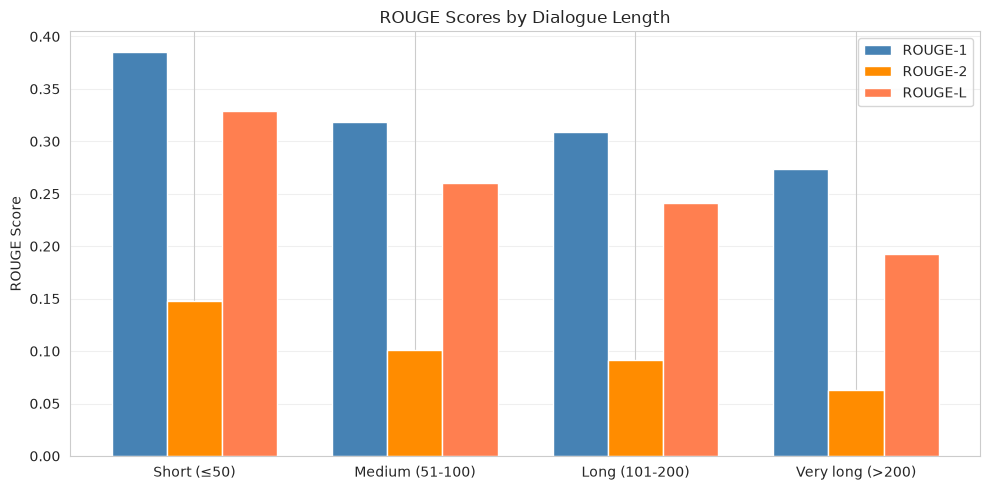


Interpretation:
  Short (≤50) (n=269): ROUGE-L=0.3291
  Medium (51-100) (n=264): ROUGE-L=0.2599
  Long (101-200) (n=208): ROUGE-L=0.2413
  Very long (>200) (n=78): ROUGE-L=0.1927

Note: dialogues beyond 356 tokens are truncated, so the "Very long" bucket summaries may be based on incomplete input.


In [37]:
# ROUGE by dialogue length bucket
length_buckets = [(0, 50, 'Short (≤50)'), (51, 100, 'Medium (51-100)'), (101, 200, 'Long (101-200)'), (201, 9999, 'Very long (>200)')]

bucket_results = []
for low, high, label in length_buckets:
    mask = (test_df['dialogue'].str.split().str.len() >= low) & (test_df['dialogue'].str.split().str.len() <= high)
    indices = test_df[mask].index.tolist()
    if not indices:
        continue
    bucket_preds = [test_preds[i] for i in indices]
    bucket_refs = [test_references[i] for i in indices]
    scores = rouge_metric.compute(predictions=bucket_preds, references=bucket_refs, use_stemmer=True)
    bucket_results.append({
        'Bucket': label, 'N': len(indices),
        'ROUGE-1': round(float(scores['rouge1']), 4),
        'ROUGE-2': round(float(scores['rouge2']), 4),
        'ROUGE-L': round(float(scores['rougeL']), 4),
    })

results_df = pd.DataFrame(bucket_results)
print(results_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(bucket_results))
width = 0.25
ax.bar(x - width, [r['ROUGE-1'] for r in bucket_results], width, label='ROUGE-1', color='steelblue')
ax.bar(x, [r['ROUGE-2'] for r in bucket_results], width, label='ROUGE-2', color='darkorange')
ax.bar(x + width, [r['ROUGE-L'] for r in bucket_results], width, label='ROUGE-L', color='coral')
ax.set_xticks(x); ax.set_xticklabels([r['Bucket'] for r in bucket_results])
ax.set_ylabel('ROUGE Score'); ax.set_title('ROUGE Scores by Dialogue Length')
ax.legend(); ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

# Interpretation
print('\nInterpretation:')
for r in bucket_results:
    flag = ' (small bucket — interpret with caution)' if r['N'] < 50 else ''
    print(f'  {r["Bucket"]} (n={r["N"]}): ROUGE-L={r["ROUGE-L"]:.4f}{flag}')
print('\nNote: dialogues beyond 356 tokens are truncated, so the "Very long" bucket summaries may be based on incomplete input.')


## Conclusion

### Final results

On the held-out test set, the model scored ROUGE-1 = 0.333, ROUGE-2 = 0.111, and ROUGE-L = 0.272 — below pitch targets (0.40 / 0.15 / 0.35) but above both the extractive baseline (0.227 / 0.064 / 0.202) and greedy decoding (0.324 / 0.102 / 0.262). Validation ROUGE-L rose from 0.126 at step 100 to 0.268 at the best checkpoint (step 5500). Average inference latency is 205 ms (P95: 338 ms), well under the 2-second target. Training completed all 6 epochs in 97.6 minutes with patience 10.

### Entity consistency

70.9% of model summaries contain unsupported capitalized names, compared with 7.6% for human references — a gap of +63.3 pp. The entity-consistency filter replaced 70.9% of summaries with the extractive fallback, producing hybrid ROUGE-1 of 0.273 (a drop of 0.060 absolute points). This shows the filter is useful as a diagnostic tool but not a usable mitigation at current quality levels.

### Business verdict

- **Latency: PASS** — inference latency is well under the 2-second target.
- **Quality: NOT YET READY** — scores are below targets and entity consistency needs improvement.

### Limitations

- ROUGE measures word overlap, not meaning, usefulness, or factual faithfulness.
- The BERT encoder truncates dialogues beyond 356 tokens (the 95th percentile of BERT token lengths, capped below BERT's 512-token limit), potentially losing context for longer conversations.
- The model may generate plausible but unsupported details (hallucination).
- Separate BERT and GPT-2 tokenizers add complexity and create a vocabulary mismatch.
- Cross-attention weights were newly initialized; even after 6 epochs the model has not learned to copy names reliably.
- Validation ROUGE-L plateaued near the end of training (0.260–0.268 over the last 8 evaluations), so the +0.01 gain over the MVP run is modest.
- Computational constraints limited experiments.

### Next steps

1. **BERT2BERT** — shared tokenizer eliminates the vocabulary mismatch, making name copying easier.
2. Alternative learning rates and warmup schedules.
3. Human evaluation for faithfulness, coverage, and conciseness.
4. Speaker-aware input formatting.
5. Parameter-efficient fine-tuning (LoRA, QLoRA).
6. Fine-tune on Acme-specific conversation data.
7. Decoding parameter grid search (length penalty, beam size).
